In [2]:
token = 'REMOVED_FOR_SECURITY'
username = 'Hassanat718'
repo = 'Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-'


In [3]:
!git clone https://{token}@github.com/{username}/{repo}

Cloning into 'Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


# **QUESTION 1**
Implement the pressure_temperature_envelope() function from Section 2.2.2 with full documentation and error handling.

### **Objective**
Implement a reusable `pressure_temperature_envelope()` function
with clear documentation, input validation, and appropriate error handling.

### **Implementation**
The function will follow the engineering requirements specified
in Section 2.2.2 of the course material.

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def pressure_temperature_envelope(
    p_max: float = 4467,
    p_min: float = 500,
    t_min_seabed: float = 4,
    t_max_reservoir: float = 82,
    hydrate_offset: float = 5
) -> dict:
    """
    Construct the pressure-temperature (P-T) design envelope
    for a subsea production system.

    The function generates a pressure range, calculates a
    simplified hydrate equilibrium curve, and determines the
    minimum safe operating temperature using a safety margin.

    Parameters
    ----------
    p_max : float, default=4467
        Maximum allowable operating pressure in psi.
    p_min : float, default=500
        Minimum operating pressure in psi, representing the
        slug-flow threshold.
    t_min_seabed : float, default=4
        Seabed temperature in degrees Celsius.
    t_max_reservoir : float, default=82
        Maximum reservoir temperature in degrees Celsius.
    hydrate_offset : float, default=5
        Temperature safety margin above the hydrate equilibrium
        curve in degrees Celsius.

    Returns
    -------
    dict
        Dictionary containing:
        - pressures: Pressure boundary array in psi.
        - t_hydrate: Hydrate equilibrium temperatures in °C.
        - t_safe_min: Minimum safe operating temperatures in °C.
        - p_max: Maximum operating pressure in psi.
        - p_min: Minimum operating pressure in psi.
        - t_min: Minimum seabed temperature in °C.
        - t_max: Maximum reservoir temperature in °C.

    Raises
    ------
    TypeError
        If any parameter is not a real numeric value or is Boolean.
    ValueError
        If a parameter is non-finite or if the design limits
        are physically or mathematically invalid.

    Notes
    -----
    The hydrate curve uses the simplified relationship supplied
    in Section 2.2.2:

        T_hydrate = 4 + 18 * log10(P / 200)

    This is a simplified exercise model, not a substitute for
    a validated hydrate-equilibrium calculation.
    """

    parameters = {
        "p_max": p_max,
        "p_min": p_min,
        "t_min_seabed": t_min_seabed,
        "t_max_reservoir": t_max_reservoir,
        "hydrate_offset": hydrate_offset
    }

    # Validate parameter types and values.
    for name, value in parameters.items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(
            value, (int, float, np.integer, np.floating)
        ):
            raise TypeError(
                f"{name} must be a real numeric value."
            )

        if not np.isfinite(value):
            raise ValueError(
                f"{name} must be finite."
            )

    # Validate engineering and mathematical constraints.
    if p_min <= 0:
        raise ValueError("p_min must be greater than zero.")

    if p_max <= p_min:
        raise ValueError(
            "p_max must be greater than p_min."
        )

    if t_max_reservoir <= t_min_seabed:
        raise ValueError(
            "t_max_reservoir must be greater than t_min_seabed."
        )

    if hydrate_offset < 0:
        raise ValueError(
            "hydrate_offset cannot be negative."
        )

    # Generate the pressure boundary.
    pressures = np.linspace(p_min, p_max, 100)

    # Calculate the simplified hydrate equilibrium curve.
    t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200)

    # Calculate the minimum safe operating temperature.
    t_safe = t_hydrate + hydrate_offset

    return {
        "pressures": pressures,
        "t_hydrate": t_hydrate,
        "t_safe_min": t_safe,
        "p_max": p_max,
        "p_min": p_min,
        "t_min": t_min_seabed,
        "t_max": t_max_reservoir
    }


# Create the default P-T envelope.
envelope = pressure_temperature_envelope()

print("P-T envelope generated successfully.")
print(f"Minimum pressure: {envelope['p_min']:.1f} psi")
print(f"Maximum pressure: {envelope['p_max']:.1f} psi")
print(f"Minimum seabed temperature: {envelope['t_min']:.1f} °C")
print(f"Maximum reservoir temperature: {envelope['t_max']:.1f} °C")
print(f"Number of pressure points: {len(envelope['pressures'])}")


P-T envelope generated successfully.
Minimum pressure: 500.0 psi
Maximum pressure: 4467.0 psi
Minimum seabed temperature: 4.0 °C
Maximum reservoir temperature: 82.0 °C
Number of pressure points: 100


# **Test the function**

In [5]:

# Test 1: Default parameters
result = pressure_temperature_envelope()
assert len(result["pressures"]) == 100
assert result["pressures"][0] == 500
assert result["pressures"][-1] == 4467

print("Test 1 passed: Default parameters.")


# Test 2: Custom parameters
result = pressure_temperature_envelope(
    p_min=1000,
    p_max=4000,
    hydrate_offset=3
)
assert result["pressures"][0] == 1000
assert result["pressures"][-1] == 4000
assert np.allclose(
    result["t_safe_min"],
    result["t_hydrate"] + 3
)

print("Test 2 passed: Custom parameters.")


# Test 3: Invalid pressure limits
try:
    pressure_temperature_envelope(p_min=5000, p_max=4000)
except ValueError as error:
    print(f"Test 3 passed: {error}")
else:
    raise AssertionError("Expected ValueError was not raised.")


# Test 4: Invalid parameter type
try:
    pressure_temperature_envelope(p_max="4467")
except TypeError as error:
    print(f"Test 4 passed: {error}")
else:
    raise AssertionError("Expected TypeError was not raised.")


# Test 5: Negative hydrate safety margin
try:
    pressure_temperature_envelope(hydrate_offset=-2)
except ValueError as error:
    print(f"Test 5 passed: {error}")
else:
    raise AssertionError("Expected ValueError was not raised.")

Test 1 passed: Default parameters.
Test 2 passed: Custom parameters.
Test 3 passed: p_max must be greater than p_min.
Test 4 passed: p_max must be a real numeric value.
Test 5 passed: hydrate_offset cannot be negative.



## **What Makes This Implementation Better?**

| Improvement | Why It Matters |
|---|---|
| Complete docstring | Documents the function, parameters, units, outputs, and exceptions. |
| Type validation | Rejects invalid input types. |
| Finite-value checks | Prevents NaN and infinite values from affecting calculations. |
| Engineering limit checks | Ensures valid pressure and temperature limits. |
| Custom parameters | Allows flexibility for different design conditions. |
| Automated tests | Verifies correct outputs and error handling. |

**Limitation:** The function does not yet enforce all operating constraints. The seabed temperature is returned but not applied as a boundary, and MAOP is assumed to be `p_max` rather than independently verified.


# **QUESTION 2**
Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9 on the envelope.

# **Jumper Operating Data**

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

jumpers = pd.DataFrame({
    "Jumper": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
    "Pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "Temperature_C": [65, 72, 58, 55, 78, 68]
})

jumpers


,Jumper,Pressure_psi,Temperature_C
0,J-001,4200,65
1,J-002,4400,72
2,J-003,3800,58
3,J-004,3200,55
4,J-005,4467,78
5,J-006,4100,68


# **Plot the 2D P–T envelope**

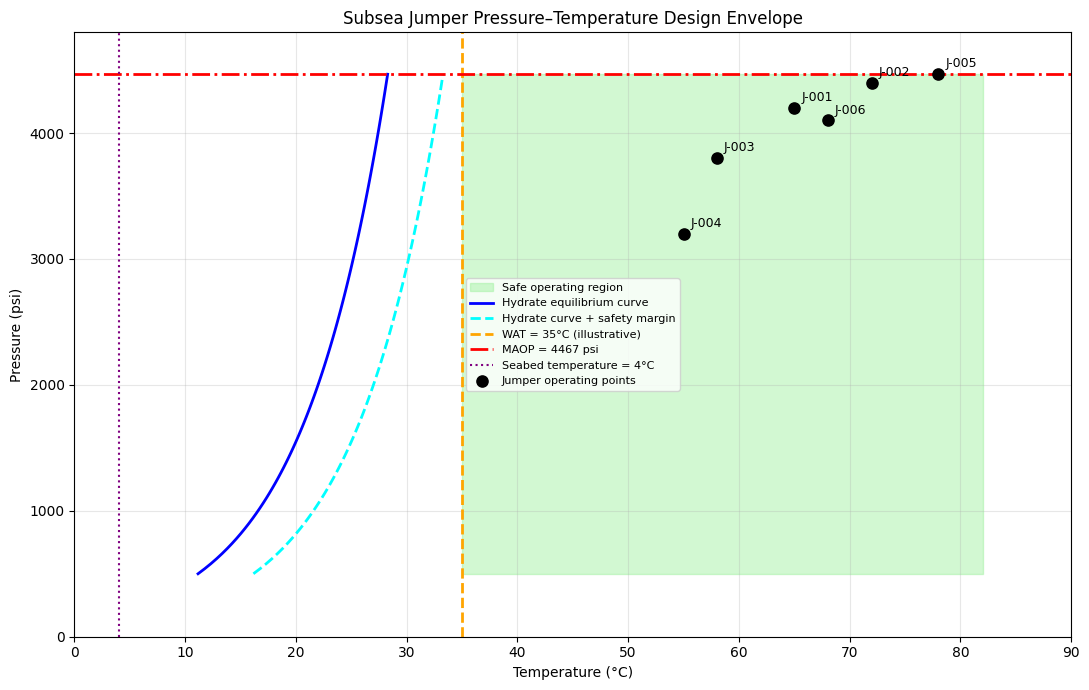

In [7]:

# Generate the envelope using the Q1 function
envelope = pressure_temperature_envelope()

# Illustrative assumption only: replace with the specified WAT
wat_temp = 35  # degrees Celsius

pressures = envelope["pressures"]
t_hydrate = envelope["t_hydrate"]
t_safe = envelope["t_safe_min"]
t_max = envelope["t_max"]

# Minimum permitted temperature at each pressure
t_lower = np.maximum(t_safe, wat_temp)

# Create the plot
fig, ax = plt.subplots(figsize=(11, 7))

# Safe operating region
ax.fill_betweenx(
    pressures,
    t_lower,
    t_max,
    color="lightgreen",
    alpha=0.4,
    label="Safe operating region"
)

# Hydrate equilibrium curve
ax.plot(
    t_hydrate,
    pressures,
    color="blue",
    linewidth=2,
    label="Hydrate equilibrium curve"
)

# Minimum safe temperature after hydrate safety margin
ax.plot(
    t_safe,
    pressures,
    color="cyan",
    linestyle="--",
    linewidth=2,
    label="Hydrate curve + safety margin"
)

# WAT boundary
ax.axvline(
    wat_temp,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"WAT = {wat_temp}°C (illustrative)"
)

# MAOP boundary
ax.axhline(
    envelope["p_max"],
    color="red",
    linestyle="-.",
    linewidth=2,
    label=f"MAOP = {envelope['p_max']} psi"
)

# Seabed temperature boundary
ax.axvline(
    envelope["t_min"],
    color="purple",
    linestyle=":",
    label=f"Seabed temperature = {envelope['t_min']}°C"
)

# Plot and label the six jumper operating points
ax.scatter(
    jumpers["Temperature_C"],
    jumpers["Pressure_psi"],
    color="black",
    s=65,
    zorder=5,
    label="Jumper operating points"
)

for _, row in jumpers.iterrows():
    ax.annotate(
        row["Jumper"],
        (row["Temperature_C"], row["Pressure_psi"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Subsea Jumper Pressure–Temperature Design Envelope")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Pressure (psi)")
ax.set_xlim(0, 90)
ax.set_ylim(0, 4800)

ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

# **ExplainIing the plot**


### **Interpretation**

The plot shows the hydrate equilibrium curve, the minimum safe
temperature boundary, the assumed WAT, the MAOP boundary, and
the six jumper operating points.

The shaded region represents the assumed safe operating region,
where pressure is within the specified limits and temperature
is above the hydrate safety boundary and WAT, but below the
maximum reservoir temperature.

The jumper points can be compared against these boundaries to
identify potential operating-envelope violations.

**Assumption:** WAT is set to 35°C for illustration only.
The actual WAT must be confirmed from the design data.


# **QUESTION 3**
3.Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.

# **Add flow-rate data**

In [8]:
# Copy the six jumper operating points from Q2
jumpers_3d = jumpers.copy()

# Illustrative flow rates only; replace with supplied data if available
jumpers_3d["Flow_Rate"] = [120, 135, 110, 95, 140, 125]

jumpers_3d


,Jumper,Pressure_psi,Temperature_C,Flow_Rate
0,J-001,4200,65,120
1,J-002,4400,72,135
2,J-003,3800,58,110
3,J-004,3200,55,95
4,J-005,4467,78,140
5,J-006,4100,68,125


# **Prepare the data**

In [11]:

import numpy as np
import matplotlib.pyplot as plt

jumpers_3d = jumpers.copy()

# Illustrative flow rates only; actual values were not supplied
jumpers_3d["Flow_Rate_bpd"] = [12000, 15000, 10000, 8000, 18000, 13000]

# Validate flow rates against the data dictionary
assert jumpers_3d["Flow_Rate_bpd"].between(0, 40000).all()

print("Flow-rate values are within the valid data range.")


Flow-rate values are within the valid data range.


# **Classify the operating points**

In [12]:

wat_temp = 35  # Illustrative WAT assumption from Q2

pressure = jumpers_3d["Pressure_psi"]
temperature = jumpers_3d["Temperature_C"]

t_hydrate_points = 4.0 + 18.0 * np.log10(pressure / 200)
t_safe_points = t_hydrate_points + 5

within_envelope = (
    (pressure >= envelope["p_min"]) &
    (pressure <= envelope["p_max"]) &
    (temperature >= t_safe_points) &
    (temperature >= wat_temp) &
    (temperature <= envelope["t_max"])
)

jumpers_3d["Envelope_Status"] = np.where(
    within_envelope,
    "Within envelope",
    "Outside envelope"
)

jumpers_3d[
    ["Jumper", "Pressure_psi", "Temperature_C",
     "Flow_Rate_bpd", "Envelope_Status"]
]


,Jumper,Pressure_psi,Temperature_C,Flow_Rate_bpd,Envelope_Status
0,J-001,4200,65,12000,Within envelope
1,J-002,4400,72,15000,Within envelope
2,J-003,3800,58,10000,Within envelope
3,J-004,3200,55,8000,Within envelope
4,J-005,4467,78,18000,Within envelope
5,J-006,4100,68,13000,Within envelope


In [9]:
# Define the illustrative WAT used in Q2
wat_temp = 35  # °C; replace with actual design value if available

# Calculate the minimum permitted temperature for each pressure
t_hydrate_points = (
    4.0 + 18.0 * np.log10(
        jumpers_3d["Pressure_psi"] / 200
    )
)

t_safe_points = t_hydrate_points + 5

# Classify operating points
jumpers_3d["Envelope_Status"] = np.where(
    (jumpers_3d["Pressure_psi"] >= envelope["p_min"]) &
    (jumpers_3d["Pressure_psi"] <= envelope["p_max"]) &
    (jumpers_3d["Temperature_C"] >= t_safe_points) &
    (jumpers_3d["Temperature_C"] >= wat_temp) &
    (jumpers_3d["Temperature_C"] <= envelope["t_max"]),
    "Within envelope",
    "Outside envelope"
)

jumpers_3d[
    ["Jumper", "Pressure_psi", "Temperature_C",
     "Flow_Rate", "Envelope_Status"]
]


,Jumper,Pressure_psi,Temperature_C,Flow_Rate,Envelope_Status
0,J-001,4200,65,120,Within envelope
1,J-002,4400,72,135,Within envelope
2,J-003,3800,58,110,Within envelope
3,J-004,3200,55,95,Within envelope
4,J-005,4467,78,140,Within envelope
5,J-006,4100,68,125,Within envelope


# **Create the 3D scatter plot**

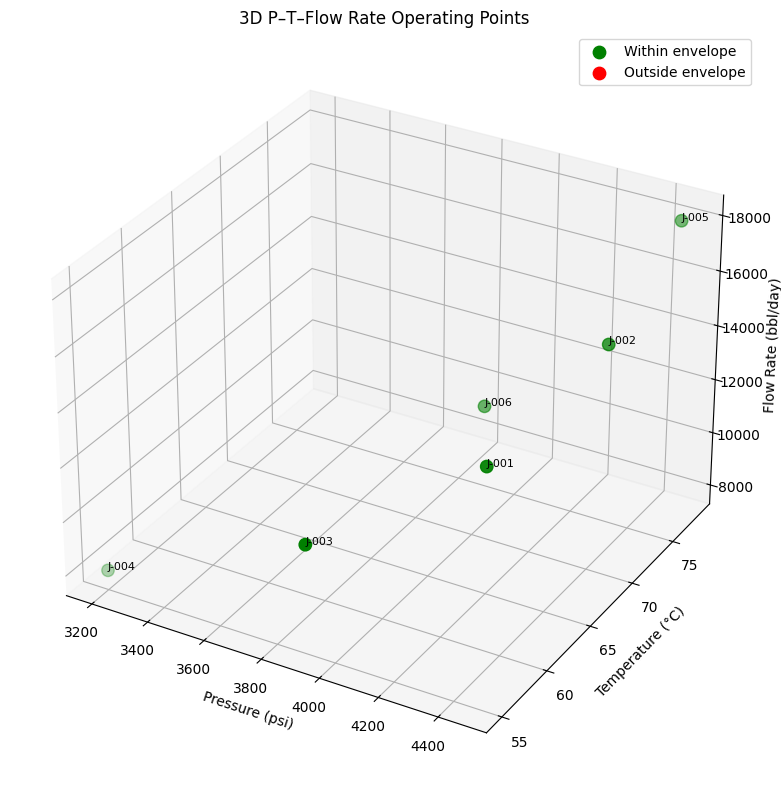

In [13]:

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

colors = {
    "Within envelope": "green",
    "Outside envelope": "red"
}

for status, color in colors.items():
    subset = jumpers_3d[
        jumpers_3d["Envelope_Status"] == status
    ]

    ax.scatter(
        subset["Pressure_psi"],
        subset["Temperature_C"],
        subset["Flow_Rate_bpd"],
        c=color,
        s=80,
        label=status
    )

for _, row in jumpers_3d.iterrows():
    ax.text(
        row["Pressure_psi"],
        row["Temperature_C"],
        row["Flow_Rate_bpd"],
        row["Jumper"],
        fontsize=8
    )

ax.set_title("3D P–T–Flow Rate Operating Points")
ax.set_xlabel("Pressure (psi)")
ax.set_ylabel("Temperature (°C)")
ax.set_zlabel("Flow Rate (bbl/day)")
ax.legend()

plt.tight_layout()
plt.show()


# **Interpretation**




The 3D scatter plot shows the six jumper operating points using
pressure, temperature, and flow rate. Green points represent
conditions within the defined pressure-temperature envelope,
while red points represent conditions outside it.

Flow rates were illustrative because Table 2.9 did not provide
actual flow-rate values. The data dictionary's 0–40,000 bbl/day
range was used for data validation, not as a safe operating limit.

**Limitation:** Flow-rate compliance cannot be independently
assessed without an engineering design limit.

# **QUESTION 4**
Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.


# **Implement the function**

In [17]:

import pandas as pd
import numpy as np


def calculate_envelope_compliance(
    df: pd.DataFrame,
    pressure_min: float = 500,
    pressure_max: float = 4467,
    temperature_min: float = 4,
    temperature_max: float = 82,
    flow_rate_min: float = 0,
    flow_rate_max: float = 40000
) -> dict:
    """
    Calculate the percentage of observations within the specified
    operating limits for each available parameter.

    Parameters
    ----------
    df : pandas.DataFrame
        Operating data containing pressure, temperature, and/or
        flow-rate columns.
    pressure_min, pressure_max : float
        Permitted pressure range in psi.
    temperature_min, temperature_max : float
        Permitted temperature range in degrees Celsius.
    flow_rate_min, flow_rate_max : float
        Valid flow-rate range in barrels per day.

    Returns
    -------
    dict
        Percentage of valid observations within the specified
        limits for each available parameter.

    Raises
    ------
    TypeError
        If df is not a pandas DataFrame.
    ValueError
        If the DataFrame is empty or a limit is invalid.

    Notes
    -----
    Missing or non-numeric observations are excluded from the
    denominator. Flow-rate compliance uses the supplied range,
    which may represent data-validity limits rather than a
    verified engineering safety envelope.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if df.empty:
        raise ValueError("df must not be empty.")

    limits = {
        "pressure_psi": (pressure_min, pressure_max),
        "temperature_c": (temperature_min, temperature_max),
        "flow_rate_bpd": (flow_rate_min, flow_rate_max)
    }

    for column, (lower, upper) in limits.items():
        if (
            isinstance(lower, (bool, np.bool_)) or
            isinstance(upper, (bool, np.bool_)) or
            not isinstance(lower, (int, float, np.number)) or
            not isinstance(upper, (int, float, np.number))
        ):
            raise TypeError(
                f"Limits for {column} must be numeric."
            )

        if not np.isfinite(lower) or not np.isfinite(upper):
            raise ValueError(
                f"Limits for {column} must be finite."
            )

        if lower > upper:
            raise ValueError(
                f"Minimum limit cannot exceed maximum for {column}."
            )

    results = {}

    for column, (lower, upper) in limits.items():
        if column not in df.columns:
            continue

        values = pd.to_numeric(df[column], errors="coerce")
        valid = values.notna() & np.isfinite(values)

        if valid.sum() == 0:
            results[column] = np.nan
            continue

        within_limits = (
            (values[valid] >= lower) &
            (values[valid] <= upper)
        )

        results[column] = (
            within_limits.sum() / valid.sum()
        ) * 100

    if not results:
        raise ValueError(
            "DataFrame contains none of the supported columns: "
            "'pressure_psi', 'temperature_c', 'flow_rate_bpd'."
        )

    return results


# **Test the function**

In [18]:
# Sample operating data for testing
sample_data = pd.DataFrame({
    "pressure_psi": [1000, 2000, 4467, 4700, 3000],
    "temperature_c": [20, 40, 60, 90, 50],
    "flow_rate_bpd": [10000, 20000, 40000, 45000, 15000]
})

compliance = calculate_envelope_compliance(sample_data)

for parameter, percentage in compliance.items():
    print(f"{parameter}: {percentage:.1f}%")


pressure_psi: 80.0%
temperature_c: 80.0%
flow_rate_bpd: 80.0%


# **Test error handling**

In [20]:
# Test empty DataFrame
try:
    calculate_envelope_compliance(pd.DataFrame())
except ValueError as error:
    print("Empty-data test passed:", error)


# Test invalid pressure limits
try:
    calculate_envelope_compliance(
        sample_data,
        pressure_min=5000,
        pressure_max=1000
    )
except ValueError as error:
    print("Invalid-limit test passed:", error)

Empty-data test passed: df must not be empty.
Invalid-limit test passed: Minimum limit cannot exceed maximum for pressure_psi.



### **Interpretation**

The function calculates the percentage of valid observations
within the specified operating limits for each available
parameter. It excludes missing and non-numeric values from
the calculation and validates the input DataFrame and limits.

A higher percentage indicates that a parameter remained within
its specified limits for a greater proportion of recorded
observations.

**Limitation:** Pressure and temperature limits are based on the
exercise assumptions. The flow-rate range represents the data
dictionary's valid range, not a confirmed engineering safety
limit. Individual parameter percentages do not establish that
all parameters were simultaneously within the design envelope.


In [22]:
%ls

Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-/
sample_data/


In [25]:
%cd /content/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-

/content/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-


In [ ]:
!mv

In [26]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
!git add --all

In [ ]:
!git commit -m "Module 2 knowledge check responses to the Module 2 knowledge check"

In [ ]:
!git push main